# Conecta+ 

Estimar el riesgo de cancelacion, decidir a quien contactar y cuantificar el valor esperado de la campaña de retencion.

Fundamentos:

- Una fila de modelado representa un cliente en una fecha de corte.
- Cada variable usa exclusivamente informacion disponible hasta esa fecha.
- La validacion respeta el orden temporal de los datos.
- Las probabilidades se calibran porque alimentan directamente una decision economica.
- La integracion de tickets aprovecha tanto variables estructuradas como el texto escrito por el cliente.


## 1. Data load



In [2]:
from pathlib import Path
from collections import Counter
from IPython.display import display
import gzip
import json
import sqlite3
import unicodedata
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
DATA_DATE = pd.Timestamp("2025-12-31")

if Path("datos_conecta.zip").exists() and not Path("datos/conecta.db").exists():
    import zipfile
    Path("datos").mkdir(exist_ok=True)
    with zipfile.ZipFile("datos_conecta.zip") as archive:
        archive.extractall("datos")

candidate_dirs = [Path("datos"), Path("datos_conecta")]
DATA_DIR = next((path for path in candidate_dirs if (path / "conecta.db").exists()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "DB not found."
    )

print("Data dir:", DATA_DIR.resolve())

Data dir: C:\Users\USUARIO\Documents\NttData_SrDS_test\datos


In [3]:
con = sqlite3.connect(DATA_DIR / "conecta.db")
table_names = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con
)["name"].tolist()

sql = {
    table: pd.read_sql_query(f"SELECT * FROM {table}", con)
    for table in table_names
}

clientes = sql["clientes"].copy()
suscripciones = sql["suscripciones"].copy()
facturas = sql["facturas"].copy()
etiquetas = sql["etiquetas_entrenamiento"].copy()
clientes_a_puntuar = sql["clientes_a_puntuar"].copy()

with open(DATA_DIR / "tickets.jsonl", encoding="utf-8") as file:
    ticket_documents = [json.loads(line) for line in file]

eventos = pd.read_json(
    DATA_DIR / "eventos.jsonl.gz",
    lines=True,
    compression="gzip",
)

inventory = pd.DataFrame(
    [
        {
            "fuente": name,
            "filas": len(frame),
            "columnas": frame.shape[1],
            "duplicados_exactos": int(frame.duplicated().sum()),
        }
        for name, frame in sql.items()
    ]
    + [
        {
            "fuente": "tickets",
            "filas": len(ticket_documents),
            "columnas": len(set().union(*(document.keys() for document in ticket_documents))),
            "duplicados_exactos": 0,
        },
        {
            "fuente": "eventos",
            "filas": len(eventos),
            "columnas": eventos.shape[1],
            "duplicados_exactos": int(eventos.duplicated().sum()),
        },
    ]
)

display(inventory)

assert clientes["cliente_id"].is_unique
assert clientes_a_puntuar["cliente_id"].is_unique
assert set(clientes_a_puntuar["cliente_id"]).issubset(clientes["cliente_id"])
assert etiquetas["churn_90d"].isin([0, 1]).all()

,fuente,filas,columnas,duplicados_exactos
0,clientes,3000,10,0
1,clientes_a_puntuar,1529,1,0
2,etiquetas_entrenamiento,4683,3,0
3,facturas,33791,9,0
4,suscripciones,3347,6,0
5,tickets,4622,17,0
6,eventos,102469,9,1718


## 2. Normalizacion & Calidad

Las fuentes provienen de sistemas distintos. Se normalizan claves, fechas, ciudades y las dos estructuras de tickets. Los registros repetidos por recarga se resuelven de forma explicita.


In [3]:
def remove_accents(value):
    if pd.isna(value):
        return value
    return "".join(
        char for char in unicodedata.normalize("NFKD", str(value))
        if not unicodedata.combining(char)
    )


def normalize_city(value):
    if pd.isna(value):
        return "Desconocida"
    key = remove_accents(value).lower().strip().replace(".", "")
    mapping = {
        "bogota": "Bogota",
        "bogota dc": "Bogota",
        "medellin": "Medellin",
        "cali": "Cali",
        "santiago de cali": "Cali",
        "barranquilla": "Barranquilla",
        "b/quilla": "Barranquilla",
        "bucaramanga": "Bucaramanga",
        "pereira": "Pereira",
    }
    return mapping.get(key, str(value).strip().title())


def to_bogota_naive(series):
    return (
        pd.to_datetime(series, errors="coerce", utc=True)
        .dt.tz_convert("America/Bogota")
        .dt.tz_localize(None)
    )


clientes["fecha_alta"] = pd.to_datetime(clientes["fecha_alta"], errors="coerce")
clientes["fecha_contacto_retencion"] = pd.to_datetime(
    clientes["fecha_contacto_retencion"], errors="coerce"
)
clientes["ciudad_norm"] = clientes["ciudad"].map(normalize_city)
clientes["edad_invalida"] = (~clientes["edad"].between(18, 100)).astype(int)
clientes["edad_limpia"] = clientes["edad"].where(clientes["edad"].between(18, 100))

for column in ["fecha_inicio", "fecha_fin"]:
    suscripciones[column] = pd.to_datetime(suscripciones[column], errors="coerce")

for column in ["fecha_vencimiento", "fecha_pago", "fecha_carga"]:
    facturas[column] = pd.to_datetime(facturas[column], errors="coerce")

# Las copias tienen el mismo contenido de negocio y una fecha de carga posterior.
# Se conservan aqui para resolverlas dentro de cada corte sin usar cargas futuras.
invoice_duplicate_rows = int(facturas.duplicated("factura_id").sum())

normalized_tickets = []
for document in ticket_documents:
    if "ticket_id" in document:
        normalized_tickets.append(
            {
                "ticket_id": document["ticket_id"],
                "cliente_id": int(document["customer"].replace("CL-", "")),
                "fecha": document["created_at"],
                "canal": document["channel"],
                "categoria": document["category"],
                "texto_cliente": document.get("text", ""),
                "estado": document["status"],
                "fecha_resolucion": document.get("resolved_at"),
                "csat": document.get("csat"),
                "schema": "v1",
            }
        )
    else:
        customer_messages = [
            message.get("texto", "")
            for message in document.get("mensajes", [])
            if message.get("autor") == "cliente"
        ]
        satisfaction = document.get("satisfaccion") or {}
        normalized_tickets.append(
            {
                "ticket_id": document["id"],
                "cliente_id": int(document["cliente"]["id"]),
                "fecha": document["fecha"],
                "canal": document["canal"],
                "categoria": document["tipo"].get("sub", document["tipo"].get("principal")),
                "texto_cliente": " ".join(customer_messages),
                "estado": document["estado"]["valor"],
                "fecha_resolucion": document["estado"].get("fecha"),
                "csat": satisfaction.get("csat"),
                "schema": "v2",
            }
        )

tickets = pd.DataFrame(normalized_tickets)
tickets["fecha"] = to_bogota_naive(tickets["fecha"])
tickets["fecha_resolucion"] = to_bogota_naive(tickets["fecha_resolucion"])
tickets["estado_norm"] = tickets["estado"].replace(
    {"open": "abierto", "closed": "resuelto"}
)
tickets["resolucion_horas"] = (
    tickets["fecha_resolucion"] - tickets["fecha"]
).dt.total_seconds() / 3600

eventos["ts"] = to_bogota_naive(eventos["ts"])
event_duplicates = int(eventos.duplicated().sum())
eventos = eventos.drop_duplicates().reset_index(drop=True)

quality_summary = pd.DataFrame(
    {
        "hallazgo": [
            "Edades fuera de 18-100",
            "Facturas duplicadas eliminadas",
            "Eventos exactos duplicados eliminados",
            "Esquemas principales de tickets",
            "Variantes originales de ciudad",
        ],
        "cantidad": [
            int(clientes["edad_invalida"].sum()),
            invoice_duplicate_rows,
            event_duplicates,
            tickets["schema"].nunique(),
            clientes["ciudad"].nunique(),
        ],
    }
)
display(quality_summary)

print("Ciudades despues de normalizar:")
display(clientes["ciudad_norm"].value_counts().rename("clientes").to_frame())

,hallazgo,cantidad
0,Edades fuera de 18-100,63
1,Facturas duplicadas eliminadas,630
2,Eventos exactos duplicados eliminados,1718
3,Esquemas principales de tickets,2
4,Variantes originales de ciudad,17


Ciudades despues de normalizar:


,clientes
ciudad_norm,
Bogota,1118
Medellin,604
Cali,443
Barranquilla,432
Bucaramanga,214
Pereira,189


### Riesgo de fuga de informacion

`estado_actual` describe el estado observado al final de 2025 y no se utiliza para construir observaciones historicas. Los campos de retencion solo se consideran conocidos cuando la fecha de contacto es anterior al corte. El indicador se audita, pero se excluye del modelo principal porque el contacto puede modificar el resultado observado.


In [4]:
leakage_audit = []
for cutoff, group in etiquetas.groupby("fecha_corte"):
    joined = group.merge(
        clientes[["cliente_id", "contactado_por_retencion", "fecha_contacto_retencion"]],
        on="cliente_id",
        how="left",
    )
    cutoff_ts = pd.Timestamp(cutoff)
    known_before = joined["fecha_contacto_retencion"].le(cutoff_ts).fillna(False)
    leakage_audit.append(
        {
            "fecha_corte": cutoff,
            "marcados_contactados": int(joined["contactado_por_retencion"].sum()),
            "contactos_conocidos_al_corte": int(known_before.sum()),
            "contactos_registrados_despues": int(
                (joined["contactado_por_retencion"].eq(1) & ~known_before).sum()
            ),
        }
    )

display(pd.DataFrame(leakage_audit))

,fecha_corte,marcados_contactados,contactos_conocidos_al_corte,contactos_registrados_despues
0,2025-03-31,312,18,294
1,2025-06-30,315,30,285
2,2025-09-30,212,34,178


## 3. Construccion de snapshots

La misma funcion se utiliza para las tres fechas de entrenamiento y para diciembre. Esto asegura que entrenamiento y puntuacion sigan las mismas reglas.


In [5]:
def merge_features(base, features):
    return base.merge(features, on="cliente_id", how="left", validate="one_to_one")


def grouped_features(frame, prefix, aggregations):
    if frame.empty:
        return pd.DataFrame(columns=["cliente_id"] + list(aggregations))
    named_aggregations = {
        f"{prefix}_{name}": specification
        for name, specification in aggregations.items()
    }
    return frame.groupby("cliente_id").agg(**named_aggregations).reset_index()


def build_snapshot(cutoff, customer_ids):
    cutoff = pd.Timestamp(cutoff)
    cutoff_end = cutoff + pd.Timedelta(days=1) - pd.Timedelta(microseconds=1)
    customer_ids = pd.Index(pd.Series(customer_ids).astype(int).unique())

    base_columns = [
        "cliente_id",
        "fecha_alta",
        "segmento",
        "ciudad_norm",
        "edad_limpia",
        "edad_invalida",
        "canal_adquisicion",
        "plataforma_principal",
        "fecha_contacto_retencion",
    ]
    base = (
        clientes.loc[clientes["cliente_id"].isin(customer_ids), base_columns]
        .copy()
        .sort_values("cliente_id")
    )
    if len(base) != len(customer_ids):
        raise ValueError("Existen clientes del snapshot ausentes en la tabla clientes.")

    base["fecha_corte"] = cutoff
    base["antiguedad_cliente_dias"] = (cutoff - base["fecha_alta"]).dt.days.clip(lower=0)
    base["contacto_retencion_previo"] = (
        base["fecha_contacto_retencion"].notna()
        & base["fecha_contacto_retencion"].le(cutoff_end)
    ).astype(int)
    base = base.drop(columns=["fecha_alta", "fecha_contacto_retencion"])

    # Suscripciones conocidas a la fecha de corte.
    subscription_history = suscripciones.loc[
        suscripciones["cliente_id"].isin(customer_ids)
        & suscripciones["fecha_inicio"].le(cutoff_end)
    ].copy()
    subscription_history["terminada_al_corte"] = (
        subscription_history["fecha_fin"].notna()
        & subscription_history["fecha_fin"].le(cutoff_end)
    ).astype(int)

    sub_agg = grouped_features(
        subscription_history,
        "sub",
        {
            "total_historicas": ("suscripcion_id", "nunique"),
            "terminadas": ("terminada_al_corte", "sum"),
            "planes_distintos": ("plan", "nunique"),
        },
    )
    base = merge_features(base, sub_agg)

    current_subscriptions = subscription_history.loc[
        subscription_history["fecha_fin"].isna()
        | subscription_history["fecha_fin"].gt(cutoff_end)
    ].copy()
    current_subscriptions = (
        current_subscriptions.sort_values(["cliente_id", "fecha_inicio"])
        .drop_duplicates("cliente_id", keep="last")
    )
    current_subscriptions["antiguedad_plan_dias"] = (
        cutoff - current_subscriptions["fecha_inicio"]
    ).dt.days.clip(lower=0)
    base = merge_features(
        base,
        current_subscriptions[
            ["cliente_id", "plan", "antiguedad_plan_dias"]
        ].rename(columns={"plan": "plan_actual"}),
    )

    ended = subscription_history.loc[subscription_history["terminada_al_corte"].eq(1)].copy()
    if not ended.empty:
        last_ended = (
            ended.sort_values(["cliente_id", "fecha_fin"])
            .drop_duplicates("cliente_id", keep="last")
            [["cliente_id", "motivo_cancelacion"]]
            .rename(columns={"motivo_cancelacion": "ultimo_motivo_cierre"})
        )
        base = merge_features(base, last_ended)

    # Facturas disponibles al corte. Una fecha de pago futura se censura.
    invoice_history = facturas.loc[
        facturas["cliente_id"].isin(customer_ids)
        & facturas["fecha_carga"].le(cutoff_end)
        & facturas["fecha_vencimiento"].le(cutoff_end)
    ].copy()
    invoice_history = (
        invoice_history.sort_values(["factura_id", "fecha_carga"])
        .drop_duplicates("factura_id", keep="last")
    )
    invoice_history["pagada_al_corte"] = (
        invoice_history["fecha_pago"].notna()
        & invoice_history["fecha_pago"].le(cutoff_end)
    ).astype(int)
    invoice_history["vencida_sin_pago"] = (
        invoice_history["pagada_al_corte"].eq(0)
        & invoice_history["fecha_vencimiento"].lt(cutoff_end)
    ).astype(int)
    effective_payment_date = invoice_history["fecha_pago"].where(
        invoice_history["pagada_al_corte"].eq(1), cutoff_end
    )
    invoice_history["dias_mora_al_corte"] = (
        effective_payment_date - invoice_history["fecha_vencimiento"]
    ).dt.days.clip(lower=0)
    invoice_history["pago_tardio"] = (
        invoice_history["pagada_al_corte"].eq(1)
        & invoice_history["dias_mora_al_corte"].gt(0)
    ).astype(int)
    invoice_history["debito_auto"] = invoice_history["metodo_pago"].eq("debito_auto").astype(int)

    for days in [30, 90, 180]:
        recent = invoice_history.loc[
            invoice_history["fecha_vencimiento"].gt(cutoff_end - pd.Timedelta(days=days))
        ]
        invoice_agg = grouped_features(
            recent,
            f"fac_{days}d",
            {
                "cantidad": ("factura_id", "nunique"),
                "monto_promedio": ("monto", "mean"),
                "monto_total": ("monto", "sum"),
                "proporcion_pagada": ("pagada_al_corte", "mean"),
                "vencidas_sin_pago": ("vencida_sin_pago", "sum"),
                "pagos_tardios": ("pago_tardio", "sum"),
                "dias_mora_promedio": ("dias_mora_al_corte", "mean"),
                "dias_mora_maximo": ("dias_mora_al_corte", "max"),
                "proporcion_debito_auto": ("debito_auto", "mean"),
            },
        )
        base = merge_features(base, invoice_agg)

    if not invoice_history.empty:
        latest_invoice = (
            invoice_history.sort_values(["cliente_id", "fecha_vencimiento", "fecha_carga"])
            .drop_duplicates("cliente_id", keep="last")
            [["cliente_id", "metodo_pago", "monto", "fecha_vencimiento", "fecha_pago"]]
            .rename(
                columns={
                    "metodo_pago": "ultimo_metodo_pago",
                    "monto": "ultimo_monto_factura",
                }
            )
        )
        latest_invoice["dias_desde_ultima_factura"] = (
            cutoff - latest_invoice["fecha_vencimiento"]
        ).dt.days.clip(lower=0)
        latest_invoice["dias_desde_ultimo_pago"] = (
            cutoff - latest_invoice["fecha_pago"].where(
                latest_invoice["fecha_pago"].le(cutoff_end)
            )
        ).dt.days
        base = merge_features(
            base,
            latest_invoice.drop(columns=["fecha_vencimiento", "fecha_pago"]),
        )

    # Tickets y texto del cliente.
    ticket_history = tickets.loc[
        tickets["cliente_id"].isin(customer_ids)
        & tickets["fecha"].le(cutoff_end)
    ].copy()
    ticket_history["abierto"] = ticket_history["estado_norm"].eq("abierto").astype(int)
    ticket_history["intencion_cancelar"] = ticket_history["categoria"].eq("cancelar").astype(int)
    ticket_history["problema_facturacion"] = ticket_history["categoria"].isin(
        ["cobro_doble", "no_reconoce_cobro"]
    ).astype(int)
    ticket_history["problema_tecnico"] = ticket_history["categoria"].isin(
        ["lentitud", "app_se_cierra"]
    ).astype(int)

    for days in [30, 90, 180]:
        recent = ticket_history.loc[
            ticket_history["fecha"].gt(cutoff_end - pd.Timedelta(days=days))
        ]
        ticket_agg = grouped_features(
            recent,
            f"tic_{days}d",
            {
                "cantidad": ("ticket_id", "nunique"),
                "abiertos": ("abierto", "sum"),
                "csat_promedio": ("csat", "mean"),
                "csat_minimo": ("csat", "min"),
                "resolucion_horas_promedio": ("resolucion_horas", "mean"),
                "cancelacion": ("intencion_cancelar", "sum"),
                "facturacion": ("problema_facturacion", "sum"),
                "tecnicos": ("problema_tecnico", "sum"),
            },
        )
        base = merge_features(base, ticket_agg)

    recent_text = ticket_history.loc[
        ticket_history["fecha"].gt(cutoff_end - pd.Timedelta(days=180))
    ]
    if not recent_text.empty:
        text_features = (
            recent_text.sort_values("fecha")
            .groupby("cliente_id")["texto_cliente"]
            .agg(lambda values: " ".join(values.fillna("").astype(str)))
            .rename("texto_tickets_180d")
            .reset_index()
        )
        base = merge_features(base, text_features)

        last_ticket = recent_text.groupby("cliente_id")["fecha"].max()
        base["dias_desde_ultimo_ticket"] = base["cliente_id"].map(
            (cutoff - last_ticket).dt.days.clip(lower=0)
        )

    # Eventos digitales.
    event_history = eventos.loc[
        eventos["cliente_id"].isin(customer_ids)
        & eventos["ts"].le(cutoff_end)
    ].copy()
    event_history["es_login"] = event_history["tipo"].eq("login").astype(int)
    event_history["es_error"] = event_history["tipo"].eq("error_app").astype(int)
    event_history["es_uso"] = event_history["tipo"].eq("uso_funcionalidad").astype(int)
    event_history["dia_activo"] = event_history["ts"].dt.floor("D")

    for days in [7, 30, 90]:
        recent = event_history.loc[
            event_history["ts"].gt(cutoff_end - pd.Timedelta(days=days))
        ]
        event_agg = grouped_features(
            recent,
            f"evt_{days}d",
            {
                "cantidad": ("event_id", "nunique"),
                "dias_activos": ("dia_activo", "nunique"),
                "logins": ("es_login", "sum"),
                "errores": ("es_error", "sum"),
                "usos": ("es_uso", "sum"),
                "duracion_total": ("duracion_seg", "sum"),
                "funcionalidades_distintas": ("funcionalidad", "nunique"),
            },
        )
        base = merge_features(base, event_agg)
        active_days = f"evt_{days}d_dias_activos"
        errors = f"evt_{days}d_errores"
        if active_days in base and errors in base:
            base[f"evt_{days}d_errores_por_dia"] = (
                base[errors] / base[active_days].replace(0, np.nan)
            )

    recent_events = event_history.loc[
        event_history["ts"].gt(cutoff_end - pd.Timedelta(days=90))
    ]
    if not recent_events.empty:
        last_event = recent_events.groupby("cliente_id")["ts"].max()
        base["dias_desde_ultimo_evento"] = base["cliente_id"].map(
            (cutoff - last_event).dt.days.clip(lower=0)
        )
        latest_version = (
            recent_events.sort_values("ts")
            .drop_duplicates("cliente_id", keep="last")
            .set_index("cliente_id")["version_app"]
        )
        base["ultima_version_app"] = base["cliente_id"].map(latest_version)

    # Tendencias y cruces faciles de explicar.
    base["cambio_logins_30_vs_90"] = (
        base.get("evt_30d_logins", 0)
        - base.get("evt_90d_logins", 0) / 3
    )
    base["cambio_errores_30_vs_90"] = (
        base.get("evt_30d_errores", 0)
        - base.get("evt_90d_errores", 0) / 3
    )
    base["presion_facturacion_90d"] = (
        base.get("fac_90d_vencidas_sin_pago", 0)
        + base.get("tic_90d_facturacion", 0)
    )
    base["friccion_digital_30d"] = (
        base.get("evt_30d_errores", 0)
        + base.get("tic_30d_tecnicos", 0)
    )

    base["texto_tickets_180d"] = base.get("texto_tickets_180d", "").fillna("")
    object_columns = [
        column for column in base.columns
        if pd.api.types.is_object_dtype(base[column].dtype)
        or pd.api.types.is_string_dtype(base[column].dtype)
    ]
    for column in object_columns:
        if column != "texto_tickets_180d":
            base[column] = base[column].fillna("Desconocido").astype(str)

    numeric_columns = base.select_dtypes(include=["number", "bool"]).columns
    base[numeric_columns] = base[numeric_columns].replace([np.inf, -np.inf], np.nan)
    return base.sort_values("cliente_id").reset_index(drop=True)


In [6]:
training_snapshots = []
for cutoff, labels_at_cutoff in etiquetas.groupby("fecha_corte", sort=True):
    snapshot = build_snapshot(cutoff, labels_at_cutoff["cliente_id"])
    snapshot = snapshot.merge(
        labels_at_cutoff[["cliente_id", "churn_90d"]],
        on="cliente_id",
        how="left",
        validate="one_to_one",
    )
    training_snapshots.append(snapshot)

modeling_data = pd.concat(training_snapshots, ignore_index=True)
scoring_data = build_snapshot(DATA_DATE, clientes_a_puntuar["cliente_id"])

feature_columns = [
    column
    for column in modeling_data.columns
    if column not in {"cliente_id", "fecha_corte", "churn_90d"}
]

assert len(modeling_data) == len(etiquetas)
assert len(scoring_data) == len(clientes_a_puntuar)
assert scoring_data["cliente_id"].is_unique
assert set(feature_columns) == set(
    column for column in scoring_data.columns
    if column not in {"cliente_id", "fecha_corte"}
)

print("Tabla de entrenamiento:", modeling_data.shape)
print("Tabla de puntuacion:", scoring_data.shape)
print("Variables candidatas:", len(feature_columns))
display(modeling_data.head())

Tabla de entrenamiento: (4683, 104)
Tabla de puntuacion: (1529, 103)
Variables candidatas: 101


,cliente_id,segmento,ciudad_norm,edad_limpia,edad_invalida,canal_adquisicion,plataforma_principal,fecha_corte,antiguedad_cliente_dias,contacto_retencion_previo,sub_total_historicas,sub_terminadas,sub_planes_distintos,plan_actual,antiguedad_plan_dias,ultimo_motivo_cierre,fac_30d_cantidad,fac_30d_monto_promedio,fac_30d_monto_total,fac_30d_proporcion_pagada,fac_30d_vencidas_sin_pago,fac_30d_pagos_tardios,fac_30d_dias_mora_promedio,fac_30d_dias_mora_maximo,fac_30d_proporcion_debito_auto,fac_90d_cantidad,fac_90d_monto_promedio,fac_90d_monto_total,fac_90d_proporcion_pagada,fac_90d_vencidas_sin_pago,fac_90d_pagos_tardios,fac_90d_dias_mora_promedio,fac_90d_dias_mora_maximo,fac_90d_proporcion_debito_auto,fac_180d_cantidad,fac_180d_monto_promedio,fac_180d_monto_total,fac_180d_proporcion_pagada,fac_180d_vencidas_sin_pago,fac_180d_pagos_tardios,fac_180d_dias_mora_promedio,fac_180d_dias_mora_maximo,fac_180d_proporcion_debito_auto,ultimo_metodo_pago,ultimo_monto_factura,dias_desde_ultima_factura,dias_desde_ultimo_pago,tic_30d_cantidad,tic_30d_abiertos,tic_30d_csat_promedio,tic_30d_csat_minimo,tic_30d_resolucion_horas_promedio,tic_30d_cancelacion,tic_30d_facturacion,tic_30d_tecnicos,tic_90d_cantidad,tic_90d_abiertos,tic_90d_csat_promedio,tic_90d_csat_minimo,tic_90d_resolucion_horas_promedio,tic_90d_cancelacion,tic_90d_facturacion,tic_90d_tecnicos,tic_180d_cantidad,tic_180d_abiertos,tic_180d_csat_promedio,tic_180d_csat_minimo,tic_180d_resolucion_horas_promedio,tic_180d_cancelacion,tic_180d_facturacion,tic_180d_tecnicos,texto_tickets_180d,dias_desde_ultimo_ticket,evt_7d_cantidad,evt_7d_dias_activos,evt_7d_logins,evt_7d_errores,evt_7d_usos,evt_7d_duracion_total,evt_7d_funcionalidades_distintas,evt_7d_errores_por_dia,evt_30d_cantidad,evt_30d_dias_activos,evt_30d_logins,evt_30d_errores,evt_30d_usos,evt_30d_duracion_total,evt_30d_funcionalidades_distintas,evt_30d_errores_por_dia,evt_90d_cantidad,evt_90d_dias_activos,evt_90d_logins,evt_90d_errores,evt_90d_usos,evt_90d_duracion_total,evt_90d_funcionalidades_distintas,evt_90d_errores_por_dia,dias_desde_ultimo_evento,ultima_version_app,cambio_logins_30_vs_90,cambio_errores_30_vs_90,presion_facturacion_90d,friccion_digital_30d,churn_90d
0,10000,Personal,Cali,39.0000,0,televenta,web,2025-03-31,805,0,2,1,2,Familiar,534,cambio_plan,1,"59,900.0000",59900,1.0000,0,0,0.0000,0,0.0000,3,"59,900.0000",179700,1.0000,0,0,0.0000,0,0.0000,7,"59,900.0000",419300,1.0000,0,0,0.0000,0,0.2857,pse,59900,16,21.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,0.0000,5.0000,5.0000,26.0000,0.0000,1.0000,0.0000,"Buenas tardes, me llegaron dos cobros este mes...",103.0000,3.0000,3.0000,2.0000,0.0000,1.0000,603.0000,1.0000,0.0000,5.0000,5.0000,4.0000,0.0000,1.0000,603.0000,1.0000,0.0000,10.0000,10.0000,9.0000,0.0000,1.0000,603.0000,1.0000,0.0000,1.0000,web,1.0000,0.0000,NaN,NaN,0
1,10001,Personal,Bogota,66.0000,0,tienda_fisica,android,2025-03-31,76,0,1,0,1,Basico,76,Desconocido,1,"19,900.0000",19900,1.0000,0,0,0.0000,0,0.0000,3,"19,900.0000",59700,1.0000,0,0,0.0000,0,0.3333,3,"19,900.0000",59700,1.0000,0,0,0.0000,0,0.3333,tarjeta,19900,16,20.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,NaN,3.0000,2.0000,2.0000,0.0000,1.0000,147.0000,1.0000,0.0000,12.0000,9.0000,6.0000,0.0000,6.0000,"1,816.0000",3.0000,0.0000,23.0000,19.0000,11.0000,0.0000,12.0000,"3,564.0000",5.0000,0.0000,3.0000,5.2.1,2.3333,0.0000,NaN,NaN,0
2,10003,Personal,Medellin,42.0000,0,televenta,ios,2025-03-31,98,0,1,0,1,Basico,98,Desconocido,1,"19,900.0000",19900,1.0000,0,0,0.0000,0,0.0000,3,"19,900.0000",59700,1.0000,0,1,13.0000,39,0.3333,4,"19,900.0000",79600,1.0000,0,2,13.7500,39,0.2500,tarjeta,19900,16,22.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,,NaN,4.0000,4.0000,3.0000,0.0000,1.0000,506.0000,1.0000,0.0000,7.0000,7.0000,5.0000,0.0000,2.0000,"1,092.0000",2.0000,0.0000,12.0000,12.0000,7.0000,0.0000,5.0000,"1,767.0000",3.000

## 4. Exploracion 

La tasa de cancelacion cambia en el tiempo, por lo que el periodo mas reciente debe tener un papel central en la validacion.


,fecha_corte,observaciones,cancelaciones,tasa_cancelacion
0,2025-03-31,1375,141,0.1025
1,2025-06-30,1615,255,0.1579
2,2025-09-30,1693,270,0.1595


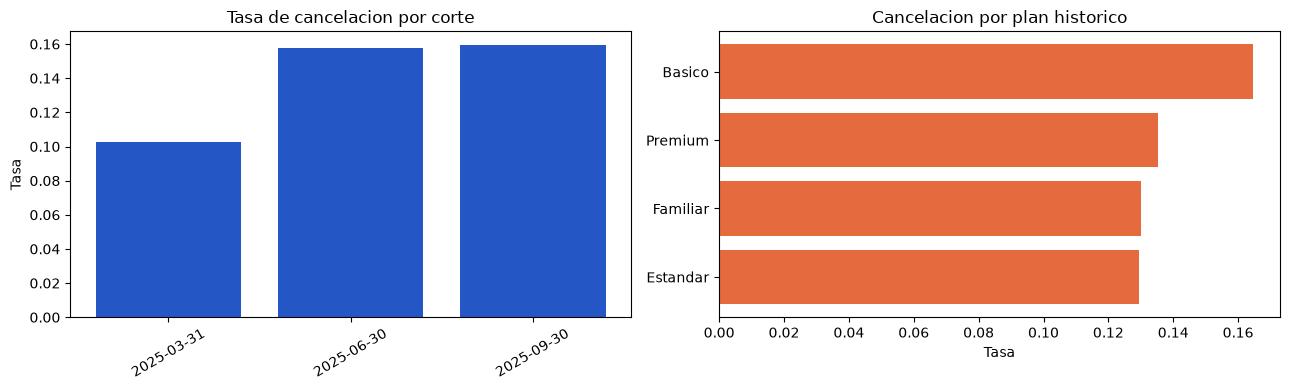

,observaciones,tasa
plan_actual,,
Estandar,1429,0.1295
Familiar,715,0.1301
Premium,1027,0.1353
Basico,1512,0.1647


In [7]:
target_summary = (
    modeling_data.groupby("fecha_corte")["churn_90d"]
    .agg(observaciones="size", cancelaciones="sum", tasa_cancelacion="mean")
    .reset_index()
)
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(
    target_summary["fecha_corte"].dt.strftime("%Y-%m-%d"),
    target_summary["tasa_cancelacion"],
    color="#2457C5",
)
axes[0].set_title("Tasa de cancelacion por corte")
axes[0].set_ylabel("Tasa")
axes[0].tick_params(axis="x", rotation=30)

plan_churn = (
    modeling_data.groupby("plan_actual", dropna=False)["churn_90d"]
    .agg(observaciones="size", tasa="mean")
    .sort_values("tasa")
)
axes[1].barh(plan_churn.index.astype(str), plan_churn["tasa"], color="#E56B3F")
axes[1].set_title("Cancelacion por plan historico")
axes[1].set_xlabel("Tasa")
plt.tight_layout()
plt.show()

display(plan_churn)

In [8]:
eda_variables = [
    "fac_90d_vencidas_sin_pago",
    "fac_90d_dias_mora_promedio",
    "tic_90d_cancelacion",
    "tic_90d_facturacion",
    "tic_90d_tecnicos",
    "evt_30d_errores",
    "evt_30d_logins",
    "dias_desde_ultimo_evento",
]

eda_rows = []
for column in eda_variables:
    if column not in modeling_data:
        continue
    observed = modeling_data[column].fillna(0)
    flag = observed.gt(0)
    for value, group in modeling_data.groupby(flag):
        eda_rows.append(
            {
                "variable": column,
                "grupo": "> 0" if value else "0 o ausente",
                "observaciones": len(group),
                "tasa_cancelacion": group["churn_90d"].mean(),
            }
        )

display(pd.DataFrame(eda_rows))

,variable,grupo,observaciones,tasa_cancelacion
0,fac_90d_vencidas_sin_pago,0 o ausente,3909,0.1371
1,fac_90d_vencidas_sin_pago,> 0,774,0.1680
2,fac_90d_dias_mora_promedio,0 o ausente,2955,0.1272
3,fac_90d_dias_mora_promedio,> 0,1728,0.1678
4,tic_90d_cancelacion,0 o ausente,4650,0.1361
5,tic_90d_cancelacion,> 0,33,1.0000
6,tic_90d_facturacion,0 o ausente,4282,0.1380
7,tic_90d_facturacion,> 0,401,0.1870
8,tic_90d_tecnicos,0 o ausente,4052,0.1333
9,tic_90d_tecnicos,> 0,631,0.1997


## 5. Modelos y validacion temporal

Se comparan tres referencias:

1. La prevalencia historica como modelo minimo.
2. Regresion logistica con variables tabulares y TF-IDF sobre el texto reciente.
3. Gradient boosting para capturar relaciones no lineales entre comportamiento, pagos y soporte.

Los folds simulan el uso real: marzo predice junio, y marzo-junio predice septiembre.


In [9]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

ID_COLUMNS = {"cliente_id", "fecha_corte", "churn_90d"}
TEXT_COLUMN = "texto_tickets_180d"
EXCLUDED_MODEL_COLUMNS = {"contacto_retencion_previo"}

candidate_columns = [
    column for column in feature_columns
    if column not in EXCLUDED_MODEL_COLUMNS
]

numeric_features = [
    column for column in candidate_columns
    if column != TEXT_COLUMN
    and pd.api.types.is_numeric_dtype(modeling_data[column])
]
categorical_features = [
    column for column in candidate_columns
    if column != TEXT_COLUMN and column not in numeric_features
]

numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=10,
            ),
        ),
    ]
)

logistic_preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        (
            "ticket_text",
            TfidfVectorizer(
                strip_accents="unicode",
                lowercase=True,
                ngram_range=(1, 2),
                min_df=3,
                max_features=4000,
                sublinear_tf=True,
            ),
            TEXT_COLUMN,
        ),
    ],
    remainder="drop",
)

logistic_model = Pipeline(
    [
        ("features", logistic_preprocessor),
        (
            "model",
            LogisticRegression(
                C=0.5,
                max_iter=2500,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

structured_preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)
structured_logistic_model = Pipeline(
    [
        ("features", structured_preprocessor),
        (
            "model",
            LogisticRegression(
                C=0.5,
                max_iter=2500,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

dense_numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
    ]
)
dense_categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Desconocido")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=20,
                sparse_output=False,
            ),
        ),
    ]
)
dense_preprocessor = ColumnTransformer(
    [
        ("numeric", dense_numeric_pipeline, numeric_features),
        ("categorical", dense_categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

gradient_model = Pipeline(
    [
        ("features", dense_preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=250,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                early_stopping=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

models = {
    "logistica_sin_texto": structured_logistic_model,
    "logistica_tfidf": logistic_model,
    "gradient_boosting": gradient_model,
}

print("Variables numericas:", len(numeric_features))
print("Variables categoricas:", len(categorical_features))

Variables numericas: 91
Variables categoricas: 8


In [10]:
PLAN_PRICES = {
    "Basico": 23_900,
    "Estandar": 34_900,
    "Premium": 49_900,
    "Familiar": 59_900,
}
CONTACT_COST = 25_000
RETENTION_PROBABILITY = 0.40
VALUE_MONTHS = 12


def probability_metrics(y_true, probabilities):
    probabilities = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
        "brier": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
    }


def business_metrics(y_true, probabilities, plans):
    monthly_value = plans.map(PLAN_PRICES).fillna(np.median(list(PLAN_PRICES.values())))
    expected_value = (
        probabilities * RETENTION_PROBABILITY * VALUE_MONTHS * monthly_value
        - CONTACT_COST
    )
    contact = expected_value.gt(0)
    realized_expected_value = (
        y_true.to_numpy() * RETENTION_PROBABILITY * VALUE_MONTHS * monthly_value.to_numpy()
        - CONTACT_COST
    )
    return {
        "contactados": int(contact.sum()),
        "tasa_contacto": float(contact.mean()),
        "valor_modelado": float(expected_value[contact].sum()),
        "valor_validacion": float(realized_expected_value[contact.to_numpy()].sum()),
    }


cutoffs = sorted(modeling_data["fecha_corte"].unique())
temporal_folds = [
    ([cutoffs[0]], cutoffs[1]),
    ([cutoffs[0], cutoffs[1]], cutoffs[2]),
]

validation_results = []
oof_predictions = {name: [] for name in models}

for train_cutoffs, validation_cutoff in temporal_folds:
    train_mask = modeling_data["fecha_corte"].isin(train_cutoffs)
    validation_mask = modeling_data["fecha_corte"].eq(validation_cutoff)

    X_train = modeling_data.loc[train_mask, candidate_columns]
    y_train = modeling_data.loc[train_mask, "churn_90d"]
    X_validation = modeling_data.loc[validation_mask, candidate_columns]
    y_validation = modeling_data.loc[validation_mask, "churn_90d"]
    validation_plans = modeling_data.loc[validation_mask, "plan_actual"]

    prior_probability = np.repeat(y_train.mean(), len(y_validation))
    row = {
        "modelo": "prevalencia",
        "validacion": pd.Timestamp(validation_cutoff).date().isoformat(),
        **probability_metrics(y_validation, prior_probability),
        **business_metrics(y_validation, prior_probability, validation_plans),
    }
    validation_results.append(row)

    for model_name, model_template in models.items():
        fitted_model = clone(model_template)
        fitted_model.fit(X_train, y_train)
        probabilities = fitted_model.predict_proba(X_validation)[:, 1]
        validation_results.append(
            {
                "modelo": model_name,
                "validacion": pd.Timestamp(validation_cutoff).date().isoformat(),
                **probability_metrics(y_validation, probabilities),
                **business_metrics(y_validation, probabilities, validation_plans),
            }
        )
        oof_predictions[model_name].append(
            pd.DataFrame(
                {
                    "row_index": modeling_data.index[validation_mask],
                    "y_true": y_validation.to_numpy(),
                    "probability": probabilities,
                    "plan_actual": validation_plans.to_numpy(),
                    "fecha_corte": validation_cutoff,
                }
            )
        )

validation_results = pd.DataFrame(validation_results)
display(validation_results.sort_values(["validacion", "modelo"]))

,modelo,validacion,roc_auc,average_precision,brier,log_loss,contactados,tasa_contacto,valor_modelado,valor_validacion
3,gradient_boosting,2025-06-30,0.6928,0.2738,0.1306,0.4312,331,0.2050,"5,852,782.4277","10,158,920.0000"
1,logistica_sin_texto,2025-06-30,0.6529,0.3092,0.1310,0.4646,327,0.2025,"9,527,762.2635","10,174,440.0000"
2,logistica_tfidf,2025-06-30,0.6539,0.3088,0.1309,0.4642,322,0.1994,"9,626,462.5570","10,586,960.0000"
0,prevalencia,2025-06-30,0.5000,0.1579,0.1360,0.4507,240,0.1486,"1,076,128.5818","3,488,160.0000"
7,gradient_boosting,2025-09-30,0.7178,0.3604,0.1212,0.3961,566,0.3343,"13,688,203.5446","15,870,160.0000"
5,logistica_sin_texto,2025-09-30,0.7009,0.3574,0.1276,0.4172,681,0.4022,"24,811,276.6086","14,816,280.0000"
6,logistica_tfidf,2025-09-30,0.7070,0.3627,0.1265,0.4132,689,0.4070,"24,696,347.9823","15,617,080.0000"
4,prevalencia,2025-09-30,0.5000,0.1595,0.1348,0.4418,651,0.3845,"6,118,140.4415","8,063,880.0000"


In [11]:
model_comparison = (
    validation_results.groupby("modelo")
    .agg(
        roc_auc=("roc_auc", "mean"),
        average_precision=("average_precision", "mean"),
        brier=("brier", "mean"),
        log_loss=("log_loss", "mean"),
        valor_validacion=("valor_validacion", "mean"),
        contactados=("contactados", "mean"),
    )
    .reset_index()
)

candidate_comparison = model_comparison.loc[
    model_comparison["modelo"].isin(models)
].copy()
candidate_comparison["rank_ap"] = candidate_comparison["average_precision"].rank(
    ascending=False, method="min"
)
candidate_comparison["rank_brier"] = candidate_comparison["brier"].rank(
    ascending=True, method="min"
)
candidate_comparison["rank_valor"] = candidate_comparison["valor_validacion"].rank(
    ascending=False, method="min"
)
candidate_comparison["rank_total"] = candidate_comparison[
    ["rank_ap", "rank_brier", "rank_valor"]
].sum(axis=1)

selected_model_name = (
    candidate_comparison.sort_values(
        ["rank_total", "brier", "average_precision"],
        ascending=[True, True, False],
    )
    .iloc[0]["modelo"]
)

display(model_comparison.sort_values("brier"))
print("Modelo seleccionado:", selected_model_name)

,modelo,roc_auc,average_precision,brier,log_loss,valor_validacion,contactados
0,gradient_boosting,0.7053,0.3171,0.1259,0.4136,"13,014,540.0000",448.5000
2,logistica_tfidf,0.6804,0.3357,0.1287,0.4387,"13,102,020.0000",505.5000
1,logistica_sin_texto,0.6769,0.3333,0.1293,0.4409,"12,495,360.0000",504.0000
3,prevalencia,0.5000,0.1587,0.1354,0.4463,"5,776,020.0000",445.5000


Modelo seleccionado: logistica_tfidf


## 6. Calibracion y entrenamiento final

La calibracion se aprende con predicciones fuera de muestra de junio y septiembre. Se aplica una transformacion logistica sobre el logit de la probabilidad original.


In [12]:
selected_oof = pd.concat(oof_predictions[selected_model_name], ignore_index=True)
raw_oof = np.clip(selected_oof["probability"].to_numpy(), 1e-6, 1 - 1e-6)
oof_logit = np.log(raw_oof / (1 - raw_oof)).reshape(-1, 1)

calibrator = LogisticRegression(C=1e6, max_iter=1000, random_state=RANDOM_STATE)
calibrator.fit(oof_logit, selected_oof["y_true"])
calibrated_oof = calibrator.predict_proba(oof_logit)[:, 1]

calibration_comparison = pd.DataFrame(
    [
        {"version": "sin_calibrar", **probability_metrics(selected_oof["y_true"], raw_oof)},
        {"version": "calibrada", **probability_metrics(selected_oof["y_true"], calibrated_oof)},
    ]
)
display(calibration_comparison)

calibration_table = pd.DataFrame(
    {
        "y": selected_oof["y_true"],
        "p": calibrated_oof,
    }
)
calibration_table["decil"] = pd.qcut(
    calibration_table["p"], q=10, duplicates="drop"
)
calibration_by_decile = (
    calibration_table.groupby("decil", observed=True)
    .agg(observaciones=("y", "size"), probabilidad_media=("p", "mean"), tasa_real=("y", "mean"))
    .reset_index()
)
display(calibration_by_decile)

final_model = clone(models[selected_model_name])
final_model.fit(modeling_data[candidate_columns], modeling_data["churn_90d"])

raw_scoring_probabilities = np.clip(
    final_model.predict_proba(scoring_data[candidate_columns])[:, 1],
    1e-6,
    1 - 1e-6,
)
scoring_logits = np.log(
    raw_scoring_probabilities / (1 - raw_scoring_probabilities)
).reshape(-1, 1)
scoring_probabilities = calibrator.predict_proba(scoring_logits)[:, 1]
print("Modelo final entrenado con", len(modeling_data), "snapshots.")

,version,roc_auc,average_precision,brier,log_loss
0,sin_calibrar,0.6735,0.3345,0.1286,0.4381
1,calibrada,0.6735,0.3345,0.1227,0.4044


,decil,observaciones,probabilidad_media,tasa_real
0,"(0.00237, 0.0672]",331,0.0483,0.0483
1,"(0.0672, 0.0903]",331,0.0795,0.0967
2,"(0.0903, 0.107]",331,0.0990,0.1118
3,"(0.107, 0.124]",330,0.1152,0.1000
4,"(0.124, 0.14]",331,0.1323,0.1118
5,"(0.14, 0.157]",331,0.1486,0.1360
6,"(0.157, 0.18]",330,0.1683,0.1788
7,"(0.18, 0.209]",331,0.1934,0.2054
8,"(0.209, 0.257]",331,0.2307,0.2387
9,"(0.257, 0.972]",331,0.3715,0.3595


Modelo final entrenado con 4683 snapshots.


## 7. Decision economica

Se contacta cuando el valor esperado es positivo:

\[
EV_i = p_i \times 0.40 \times 12 \times mensualidad_i - 25{,}000
\]

El umbral varia por plan porque el valor de retener al cliente tambien varia.


In [13]:
thresholds = pd.DataFrame(
    {
        "plan": list(PLAN_PRICES),
        "mensualidad": list(PLAN_PRICES.values()),
    }
)
thresholds["umbral_probabilidad"] = CONTACT_COST / (
    RETENTION_PROBABILITY * VALUE_MONTHS * thresholds["mensualidad"]
)
display(thresholds)

scoring_analysis = scoring_data[["cliente_id", "plan_actual"]].copy()
scoring_analysis["probabilidad"] = scoring_probabilities
scoring_analysis["mensualidad"] = (
    scoring_analysis["plan_actual"]
    .map(PLAN_PRICES)
    .fillna(np.median(list(PLAN_PRICES.values())))
)
scoring_analysis["valor_esperado_contacto"] = (
    scoring_analysis["probabilidad"]
    * RETENTION_PROBABILITY
    * VALUE_MONTHS
    * scoring_analysis["mensualidad"]
    - CONTACT_COST
)
scoring_analysis["contactar"] = scoring_analysis["valor_esperado_contacto"].gt(0).astype(int)

predicciones = scoring_analysis[["cliente_id", "probabilidad", "contactar"]].copy()
predicciones.to_csv("predicciones.csv", index=False)

business_summary = pd.Series(
    {
        "clientes_puntuados": len(scoring_analysis),
        "clientes_a_contactar": int(scoring_analysis["contactar"].sum()),
        "tasa_contacto": scoring_analysis["contactar"].mean(),
        "cancelaciones_esperadas_entre_contactados": (
            scoring_analysis.loc[scoring_analysis["contactar"].eq(1), "probabilidad"].sum()
        ),
        "retenciones_esperadas": (
            scoring_analysis.loc[scoring_analysis["contactar"].eq(1), "probabilidad"].sum()
            * RETENTION_PROBABILITY
        ),
        "costo_contactos": int(scoring_analysis["contactar"].sum()) * CONTACT_COST,
        "valor_neto_esperado": scoring_analysis.loc[
            scoring_analysis["contactar"].eq(1), "valor_esperado_contacto"
        ].sum(),
    },
    name="resultado",
)
display(business_summary.to_frame())
display(
    scoring_analysis.groupby("plan_actual")
    .agg(
        clientes=("cliente_id", "size"),
        riesgo_promedio=("probabilidad", "mean"),
        contactados=("contactar", "sum"),
        valor_esperado=("valor_esperado_contacto", lambda values: values[values > 0].sum()),
    )
    .sort_values("riesgo_promedio", ascending=False)
)
display(scoring_analysis.sort_values("valor_esperado_contacto", ascending=False).head(15))

,plan,mensualidad,umbral_probabilidad
0,Basico,23900,0.2179
1,Estandar,34900,0.1492
2,Premium,49900,0.1044
3,Familiar,59900,0.0870


,resultado
clientes_puntuados,"1,529.0000"
clientes_a_contactar,666.0000
tasa_contacto,0.4356
cancelaciones_esperadas_entre_contactados,133.3218
retenciones_esperadas,53.3287
costo_contactos,"16,650,000.0000"
valor_neto_esperado,"11,132,575.1972"


,clientes,riesgo_promedio,contactados,valor_esperado
plan_actual,,,,
Basico,471,0.1612,83,"684,935.5917"
Estandar,462,0.1469,164,"2,126,355.4787"
Premium,338,0.1458,221,"4,119,328.6611"
Familiar,258,0.1387,198,"4,201,955.4657"


,cliente_id,plan_actual,probabilidad,mensualidad,valor_esperado_contacto,contactar
1187,12360,Familiar,0.8397,59900,"216,443.6177",1
1248,12485,Premium,0.9124,49900,"193,540.3772",1
293,10601,Premium,0.9061,49900,"192,036.2279",1
679,11377,Premium,0.8703,49900,"183,445.0642",1
875,11747,Premium,0.8682,49900,"182,942.9845",1
100,10202,Estandar,0.9423,34900,"132,848.3573",1
450,10921,Estandar,0.9365,34900,"131,883.9214",1
15,10024,Estandar,0.8841,34900,"123,099.8164",1
1431,12823,Estandar,0.8692,34900,"120,614.6213",1
956,11929,Familiar,0.3788,59900,"83,915.0032",1


In [14]:
assert len(predicciones) == len(clientes_a_puntuar) == 1529
assert predicciones["cliente_id"].is_unique
assert predicciones["probabilidad"].between(0, 1).all()
assert predicciones["contactar"].isin([0, 1]).all()
assert predicciones.isna().sum().sum() == 0
assert set(predicciones["cliente_id"]) == set(clientes_a_puntuar["cliente_id"])

print("predicciones.csv validado correctamente")
display(predicciones.head())

predicciones.csv validado correctamente


,cliente_id,probabilidad,contactar
0,10000,0.1675,1
1,10003,0.1508,0
2,10005,0.2760,1
3,10006,0.0708,0
4,10007,0.2933,1


## 8. Interpretacion

La importancia se estima en el ultimo corte de validacion mediante permutacion. Esta medida responde cuanto disminuye el desempeño cuando se rompe la relacion entre una variable y el resultado.


,variable,importancia_media,desviacion
81,evt_30d_errores,0.1495,0.0156
93,evt_90d_errores_por_dia,0.0797,0.0074
77,evt_7d_errores_por_dia,0.0729,0.0094
87,evt_90d_dias_activos,0.0549,0.0083
55,tic_90d_csat_minimo,0.0513,0.0042
35,fac_180d_vencidas_sin_pago,0.0335,0.0133
54,tic_90d_csat_promedio,0.0266,0.0035
23,fac_90d_monto_promedio,0.0216,0.0069
83,evt_30d_duracion_total,0.0215,0.0092
84,evt_30d_funcionalidades_distintas,0.0203,0.0065


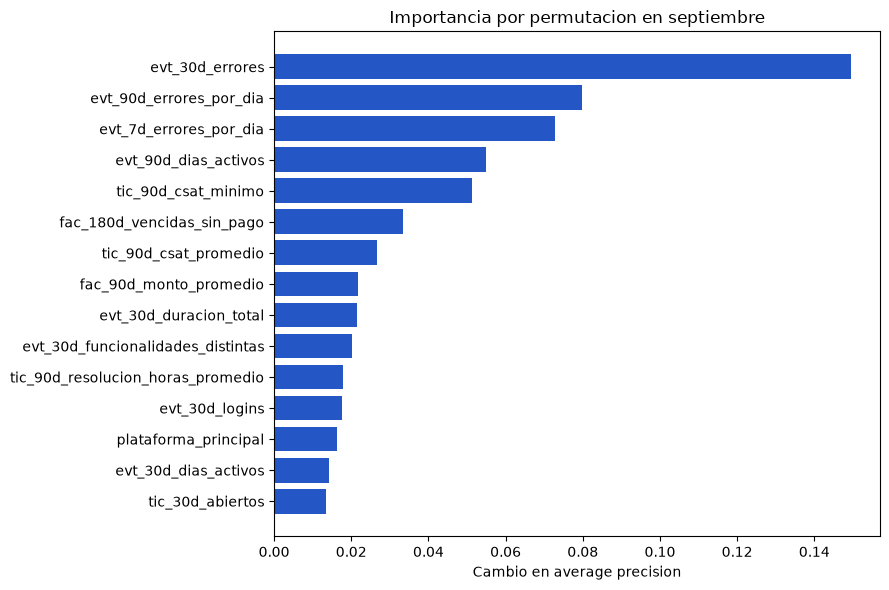

In [15]:
from sklearn.inspection import permutation_importance

last_cutoff = max(cutoffs)
interpretation_mask = modeling_data["fecha_corte"].eq(last_cutoff)
X_interpretation = modeling_data.loc[interpretation_mask, candidate_columns]
y_interpretation = modeling_data.loc[interpretation_mask, "churn_90d"]

interpretation_train_mask = modeling_data["fecha_corte"].lt(last_cutoff)
interpretation_model = clone(models[selected_model_name])
interpretation_model.fit(
    modeling_data.loc[interpretation_train_mask, candidate_columns],
    modeling_data.loc[interpretation_train_mask, "churn_90d"],
)

permutation = permutation_importance(
    interpretation_model,
    X_interpretation,
    y_interpretation,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = pd.DataFrame(
    {
        "variable": candidate_columns,
        "importancia_media": permutation.importances_mean,
        "desviacion": permutation.importances_std,
    }
).sort_values("importancia_media", ascending=False)

display(importance.head(20))

top_importance = importance.head(15).sort_values("importancia_media")
plt.figure(figsize=(9, 6))
plt.barh(top_importance["variable"], top_importance["importancia_media"], color="#2457C5")
plt.title("Importancia por permutacion en septiembre")
plt.xlabel("Cambio en average precision")
plt.tight_layout()
plt.show()

## 9. Limitaciones y operacion

- Los datos son observacionales. Las asociaciones del modelo no demuestran causalidad.
- El contacto historico de retencion puede haber modificado la cancelacion observada. Se excluye como predictor principal y se recomienda medir el efecto con un grupo de control aleatorio.
- Solo existen tres cortes de entrenamiento. El desempeño debe revisarse cuando se conozca el resultado real de diciembre.
- Los eventos de uso empiezan en enero de 2025. Las ventanas utilizadas caben dentro de ese periodo, pero no describen comportamiento anterior.
- Las probabilidades calibradas deben monitorearse por plan, segmento y periodo.

Propuesta operativa:

1. Puntuar clientes activos semanal o mensualmente.
2. Registrar version del modelo, fecha de corte y variables usadas.
3. Monitorear volumen, faltantes, categorias nuevas, deriva y calibracion.
4. Medir cancelacion y valor realizado 90 dias despues.
5. Mantener un grupo de control elegible sin contacto para estimar el efecto causal de la oferta.
6. Reentrenar trimestralmente o cuando disminuya la calibracion o el valor de negocio.


## 10. Resultado reproducible

La ejecucion completa genera `predicciones.csv` en la raiz del proyecto con una fila por cada cliente activo y las columnas requeridas.
